# Season vs embeddings: mapping smallholder farms in Togo

Silvio Kaiser, GIMA Module 1 project (Programming and Machine Learning), 2026.

Research question: can a pretrained Earth embedding identify smallholder farmland more reliably than a full
growing season of satellite imagery? The case study is Togo in 2019, with expert-drawn field polygons for
training and 306 random points, labelled by three people, as the final test.

This notebook walks through the whole workflow on the saved outputs of the pipeline in `pipeline/`. It runs in
about a minute and needs no downloads. The heavy steps (reading Sentinel-1/2 time series and embeddings over
the network, tuning, and the wall-to-wall maps) are scripts; each section names the script that produced its
table, and the scores below are recomputed from the saved predictions where that is cheap.

| Step | Script | Section |
|---|---|---|
| Regions, labels, sample table | `s00_regions.py`, `s01_labels.py` | 1 |
| Sentinel-2, Sentinel-1, embeddings, benchmark maps | `s02` to `s05` | 2 |
| Feature sets A to F | `s06_features.py` | 2 |
| Validation design, season profiles | `s07_smoke.py`, `s08_profiles.py` | 3 |
| Tuning, tree against forest | `s09_tune.py`, `s10_compare.py` | 4 |
| One-time test on the 306 points | `s12_test.py`, `s16_olmoearth.py` | 5 |
| Regional maps and areas | `s13`, `s14_areas.py`, `s17_maps_f.py` | 6 |
| Error analysis | `s15_errors.py` | 7 |

In [1]:
import inspect
import json
import sys
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from scipy.stats import binomtest

ROOT = Path.cwd().resolve()
if not (ROOT / "pipeline").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "pipeline"))

from common import PREP  # noqa: E402  data/prep in this repository
from s05_benchmarks import scores  # noqa: E402
from s14_areas import stratified  # noqa: E402

CHECKS = PREP / "checks"
pd.set_option("display.precision", 3)
pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

# Names used on the poster for the feature sets
NAMES = {
    "RF A": "A one image", "RF B": "B full season", "RF C": "C season + radar",
    "RF D": "D AlphaEarth", "RF E": "E TESSERA", "RF F": "F OlmoEarth",
    "Tree C depth 6": "Tree on C (depth 6)",
    "WorldCover 2020": "WorldCover 2020", "WorldCover 2021": "WorldCover 2021",
    "DEA crop mask 2019": "DEA crop mask 2019",
}

## 1. Problem, study area and reference data

Global cropland maps disagree on where smallholder farms in West Africa are, because the fields are small and
lie scattered among trees, fallow and savanna. The information product here is a 10 m crop / non-crop map of
two Togolese regions, Savanes (north, one rainy season) and Plateaux (south, two seasons), with an
error-adjusted cropland area. It could feed crop water use into water balances for water resource management.

The unit of analysis is the 10 m pixel. Labels come from Kerner et al. (2020): 1 276 expert-drawn polygons for
training and a simple random sample of 306 points across Togo, each labelled by three people, for testing.

In [2]:
poly = gpd.read_file(PREP / "labels.gpkg", layer="train_polygons")
test_pts = gpd.read_file(PREP / "labels.gpkg", layer="test_points")
regions = gpd.read_file(PREP / "regions.gpkg").to_crs(poly.crs)
samples = pd.read_parquet(PREP / "samples.parquet")

train_px = samples[samples.kind == "train"]
print(f"training polygons: {len(poly)} ({(poly.label == 1).sum()} crop, {(poly.label == 0).sum()} non-crop)")
print(f"training pixels:   {len(train_px)} in {train_px.poly_id.nunique()} polygons, "
      f"crop share {train_px.label.mean():.0%}")
print(f"test points:       {len(test_pts)}, crop share {test_pts.label.mean():.0%}, "
      f"unanimous {(test_pts.agreement == 'unanimous').sum()}, split {(test_pts.agreement == 'split').sum()}")
print(f"test points within 500 m of a training polygon: {(test_pts.dist_train_m < 500).sum()}")

training polygons: 1276 (688 crop, 588 non-crop)
training pixels:   71660 in 1276 polygons, crop share 24%
test points:       306, crop share 35%, unanimous 237, split 69
test points within 500 m of a training polygon: 6


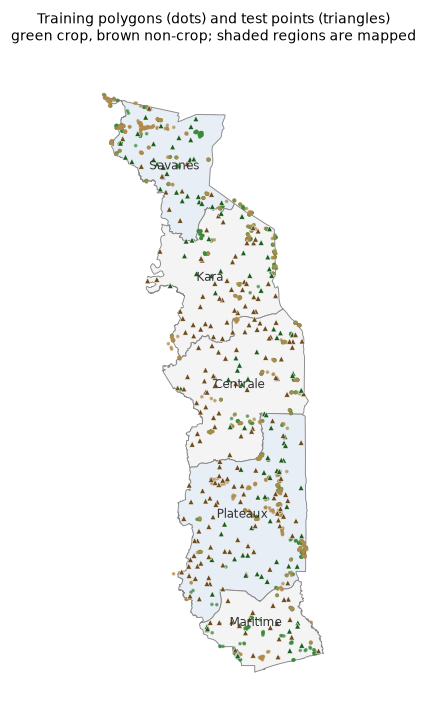

In [3]:
fig, ax = plt.subplots(figsize=(5, 7.5))
regions.plot(ax=ax, color=np.where(regions.mapped, "#e8eef5", "#f4f4f4"), edgecolor="#888", lw=0.6)
poly.assign(geometry=poly.centroid).plot(ax=ax, color=np.where(poly.label == 1, "#3a8a3a", "#b08a4a"),
                                         markersize=2, alpha=0.6)
test_pts.plot(ax=ax, color=np.where(test_pts.label == 1, "#1b5e20", "#6d4c1f"), marker="^", markersize=14,
              edgecolor="white", lw=0.3)
for _, r in regions.iterrows():
    c = r.geometry.representative_point()
    ax.annotate(r.region, (c.x, c.y), ha="center", fontsize=8, color="#333")
ax.set_axis_off()
ax.set_title("Training polygons (dots) and test points (triangles)\ngreen crop, brown non-crop; "
             "shaded regions are mapped", fontsize=9)
plt.show()

The classes are imbalanced in different ways in the two data sets. 54 % of the polygons are crop, but only
24 % of the pixels, because non-crop polygons are much larger. Training therefore caps the pixels per polygon
(section 4), which also evens out the class mix. Only 35 % of the
random test points are crop, which is the share that matters for a map of Togo. A model that calls too much
crop is therefore punished by user's accuracy, and F1 for the crop class is the headline score instead of
overall accuracy, which a "never crop" map would already push to 65 %.

## 2. Data and features

All inputs are for 2019, the year of the labels, and are read at every sample pixel by `s02` to `s05`.

- Sentinel-2 L2A (Microsoft Planetary Computer): every observation the scene classification calls clear
  (vegetation, bare soil or water). Reflectance is DN / 10 000; all 2019 scenes use processing baseline 02.12,
  which has no offset.
- Sentinel-1 RTC (Planetary Computer): VV and VH gamma0, a 3 x 3 mean in linear power as a light speckle
  filter, then dB.
- Three foundation-model embeddings, annual 2019, one vector per 10 m pixel: AlphaEarth (Google DeepMind,
  64 dimensions), TESSERA (Cambridge, 128) and OlmoEarth v1.3 (Ai2, 128).
- Benchmarks at the same points: ESA WorldCover 2020 and 2021 and the Digital Earth Africa crop mask 2019.

`s06_features.py` turns these into six feature sets for one and the same classifier:

| Set | Content | Features |
|---|---|---|
| A | one clear Sentinel-2 image after the rains (Oct-Dec) | 14 |
| B | full season: annual percentiles of every clear Sentinel-2 observation, seasonal NDVI/NDMI, harmonic fit | 68 |
| C | B plus monthly and annual Sentinel-1 statistics | 116 |
| D | AlphaEarth embedding | 64 |
| E | TESSERA embedding | 128 |
| F | OlmoEarth embedding (added after the test of A to E, see section 5) | 128 |

Missing values stay NaN (scikit-learn's trees handle them); 50 non-crop pixels that are never clear have no
optical features, and coordinates, observation counts and labels are never features. Every set uses the same
10 m grid, so values align pixel for pixel.

The season profiles below are a physical check of the prepared time series: crop polygons green up later and
brown down harder than non-crop land, and in the north the radar VH signal swings with ploughing and harvest.

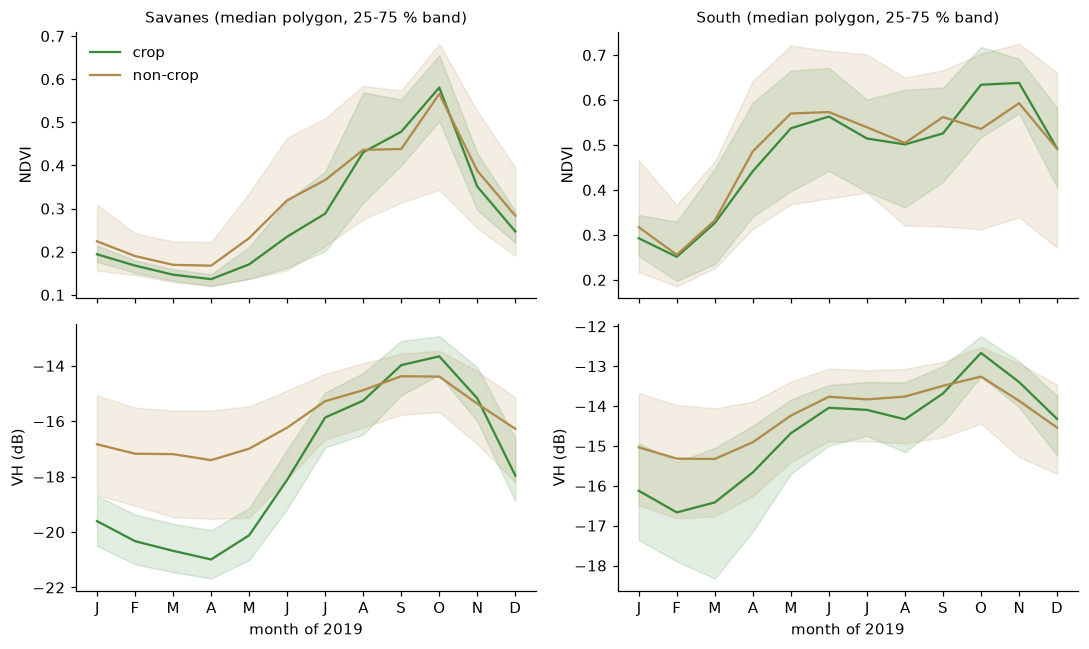

In [4]:
prof = pd.read_csv(CHECKS / "season_profiles.csv")
fig, axs = plt.subplots(2, 2, figsize=(10, 6), sharex=True)
for j, area in enumerate(["Savanes", "South"]):
    for i, (var, ylab) in enumerate([("ndvi", "NDVI"), ("vh_db", "VH (dB)")]):
        ax = axs[i, j]
        for lab, col, name in [(1, "#3a8a3a", "crop"), (0, "#b08a4a", "non-crop")]:
            d = prof[(prof.area == area) & (prof.label == lab) & (prof["var"] == var)].sort_values("month")
            ax.plot(d.month, d["median"], color=col, label=name)
            ax.fill_between(d.month, d.q25, d.q75, color=col, alpha=0.15)
        ax.set_ylabel(ylab)
        if i == 0:
            ax.set_title(f"{area} (median polygon, 25-75 % band)", fontsize=10)
for ax in axs[1]:
    ax.set_xticks(range(1, 13), list("JFMAMJJASOND"))
    ax.set_xlabel("month of 2019")
axs[0, 0].legend(frameon=False)
plt.tight_layout()
plt.show()

## 3. Validation design: keeping neighbours apart

Pixels of one field are near copies of each other, and neighbouring fields share soil, weather and farming
practice. Random folds would therefore measure memory, not skill. `s07_smoke.py` compares two grouped
designs on the training data only: folds grouped by polygon, and folds grouped by 5 km cell (a polygon takes
the cell of its centroid as a whole, so no polygon is split between folds).

In [5]:
smoke = pd.read_csv(CHECKS / "smoke_cv.csv")
sm = smoke[smoke.model == "RF"].pivot(index="set", columns="grouping", values="F1_crop")[["poly_id", "cell5km"]]
sm["drop"] = sm.poly_id - sm.cell5km
sm

grouping,poly_id,cell5km,drop
set,,,
A,0.788,0.757,0.031
B,0.860,0.799,0.060
C,0.866,0.813,0.053
D,0.941,0.893,0.048
E,0.917,0.878,0.040


Every set loses 3 to 6 points of F1 when neighbouring polygons can no longer sit on both sides of a split, so
nearby fields do leak information. Tuning and validation from here on use `GroupKFold(5)` by 5 km cell. The
test points are kept out by construction: `training_table` refuses anything but training pixels.

In [6]:
from s09_tune import cap_rows, poly_weights, training_table, weighted_scores  # noqa: E402

print(inspect.getsource(training_table))
print(inspect.getsource(cap_rows))
print(inspect.getsource(poly_weights))
print(inspect.getsource(weighted_scores))

def training_table() -> tuple[pd.DataFrame, dict[str, pd.DataFrame]]:
    """Training pixels with values in every set, and the feature table per set."""
    smp = pd.read_parquet(PREP / "samples.parquet")
    smp = smp[smp.kind == "train"]
    assert (smp.kind == "train").all() and smp.test_id.isna().all()
    cols = json.loads((FEAT / "columns.json").read_text())
    X = {s: pd.read_parquet(FEAT / f"set_{s}.parquet").set_index("sid").loc[smp.sid, cols[s]]
         for s in SETS}
    ok = np.logical_and.reduce([~X[s].isna().all(axis=1).to_numpy() for s in SETS])
    smp = smp[ok].set_index("sid")
    log.info("training pixels %d of %d kept (values in every set), %d polygons",
             ok.sum(), len(ok), smp.poly_id.nunique())
    return smp, {s: X[s].loc[smp.index] for s in SETS}

def cap_rows(meta: pd.DataFrame, cap: int, seed: int) -> pd.Index:
    return meta.sample(frac=1, random_state=seed).groupby("poly_id").head(cap).index

def poly_weights(meta: pd.DataFrame) -> np.ndarray:

Two more choices are visible here. At most `cap` pixels per polygon are drawn for training, so a few huge
non-crop polygons do not dominate the class mix; the cap is tuned. Validation always uses at most 30 pixels
per polygon and gives every polygon the weight 1, since one field should count once.

## 4. Model choice and tuning

The comparison is between inputs, so one classifier is used for all of them: a Random Forest of 300 trees from
the lecture, which handles NaN, mixed scales and correlated features without preprocessing. `s09_tune.py`
tries 12 settings per set (cap 30 or 100 pixels per polygon, `max_features` sqrt or 0.3, `min_samples_leaf`
1, 5 or 20) on the same rows and the same folds.

In [7]:
tune = pd.read_csv(CHECKS / "tune_cv.csv")
best = json.loads((CHECKS / "tune_best.json").read_text())
print("common setting:", {k: v for k, v in best["common"].items() if k in ("cap", "max_features", "min_samples_leaf")},
      f"(worst gap to a set's own best: {best['common']['worst_gap']:.3f})")
summary = (tune.sort_values("F1_crop", ascending=False).groupby("set").head(1)
           .set_index("set")[["cap", "max_features", "min_samples_leaf", "F1_crop", "F1_fold_sd", "F1_train"]]
           .sort_index())
summary["train - validation"] = summary.F1_train - summary.F1_crop
summary

common setting: {'cap': 30, 'max_features': 0.3, 'min_samples_leaf': 20} (worst gap to a set's own best: 0.006)


,cap,max_features,min_samples_leaf,F1_crop,F1_fold_sd,F1_train,train - validation
set,,,,,,,
A,30,sqrt,20,0.792,0.038,0.898,0.106
B,30,0.3,5,0.824,0.011,0.993,0.168
C,30,0.3,20,0.836,0.014,0.962,0.126
D,30,0.3,20,0.893,0.028,0.974,0.082
E,30,0.3,1,0.899,0.015,1.000,0.101


The gap between training and validation F1 shows the forests overfit the training pixels, as forests do, but
the validation spread across folds stays small (1 to 4 points). Because one common setting is within 1 point
of every set's own best, all sets use it, and no set gets an advantage from its own tuning.

A single decision tree is the readable baseline. `s10_compare.py` grows trees of several depths on set C:

In [8]:
cmp = pd.read_csv(CHECKS / "compare_tree_rf.csv")
cmp[cmp.set == "C"][["model", "depth", "F1_crop", "F1_train"]]

,model,depth,F1_crop,F1_train
0,Random Forest,NaN,0.836,0.962
1,Decision tree,3.0,0.786,0.805
2,Decision tree,4.0,0.800,0.838
3,Decision tree,6.0,0.806,0.872
4,Decision tree,8.0,0.800,0.908
5,Decision tree,NaN,0.789,0.927


In [9]:
print((CHECKS / "tree_rules_C.txt").read_text())

|--- c_vh_db_std <= 1.90
|   |--- b_ndre_p10 <= 0.18
|   |   |--- b_ndvi_amj <= 0.65
|   |   |   |--- weights: [3771.00, 260.00] class: non-crop
|   |   |--- b_ndvi_amj >  0.65
|   |   |   |--- weights: [36.00, 45.00] class: crop
|   |--- b_ndre_p10 >  0.18
|   |   |--- b_B02_p10 <= 0.04
|   |   |   |--- weights: [2549.00, 380.00] class: non-crop
|   |   |--- b_B02_p10 >  0.04
|   |   |   |--- weights: [1812.00, 1624.00] class: non-crop
|--- c_vh_db_std >  1.90
|   |--- b_ndvi_ond <= 0.19
|   |   |--- b_ndvi_ond <= 0.17
|   |   |   |--- weights: [723.00, 6.00] class: non-crop
|   |   |--- b_ndvi_ond >  0.17
|   |   |   |--- weights: [52.00, 30.00] class: non-crop
|   |--- b_ndvi_ond >  0.19
|   |   |--- b_B03_p10 <= 0.07
|   |   |   |--- weights: [785.00, 830.00] class: crop
|   |   |--- b_B03_p10 >  0.07
|   |   |   |--- weights: [951.00, 5660.00] class: crop



The best tree (depth 6) trails the forest by about 3 points. Its first split is the yearly spread of VH
backscatter, and grouped permutation importance of the set C forest agrees: the radar statistics matter most.
Columns are permuted in groups because single correlated columns would each look unimportant.

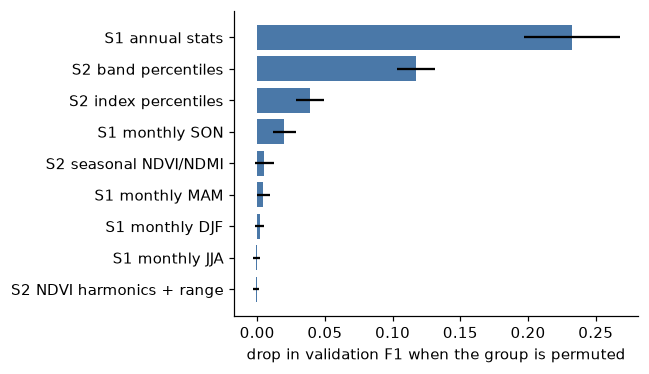

In [10]:
imp = pd.read_csv(CHECKS / "perm_importance_C.csv").sort_values("F1_drop")
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.barh(imp.group, imp.F1_drop, xerr=imp.F1_drop_sd, color="#4a78a8")
ax.set_xlabel("drop in validation F1 when the group is permuted")
plt.tight_layout()
plt.show()

## 5. The one-time test on 306 random points

`s12_test.py` fits every model once on all training pixels with the common setting and predicts the test
points once; nothing here feeds back into a choice. Set F (OlmoEarth) was added on 2 November, after the test
of A to E. It uses the setting fixed before it existed, and `s16_olmoearth.py` scores it once, so the test is
still its only look at the points, but it is reported as a later addition.

Here the scores are recomputed from the saved predictions.

In [11]:
pred = pd.read_parquet(PREP / "test_predictions.parquet").merge(
    pd.read_parquet(PREP / "test_predictions_F.parquet")[["test_id", "RF F", "RF F p_crop"]], on="test_id")
y = pred.label.to_numpy()
maps = ["WorldCover 2020", "WorldCover 2021", "DEA crop mask 2019",
        "RF A", "RF B", "RF C", "RF D", "RF E", "RF F", "Tree C depth 6"]

rows = [dict(map=NAMES[m], **scores(y, pred[m].to_numpy()), called_crop=pred[m].mean()) for m in maps]
test = pd.DataFrame(rows).set_index("map")
test[["OA", "UA_crop", "PA_crop", "F1_crop", "tp", "fp", "fn", "tn", "called_crop"]]

,OA,UA_crop,PA_crop,F1_crop,tp,fp,fn,tn,called_crop
map,,,,,,,,,
WorldCover 2020,0.810,0.875,0.528,0.659,56,8,50,192,0.209
WorldCover 2021,0.827,0.873,0.585,0.701,62,9,44,191,0.232
DEA crop mask 2019,0.807,0.747,0.670,0.706,71,24,35,176,0.310
A one image,0.732,0.590,0.745,0.658,79,55,27,145,0.438
B full season,0.807,0.682,0.830,0.749,88,41,18,159,0.422
C season + radar,0.810,0.685,0.840,0.754,89,41,17,159,0.425
D AlphaEarth,0.817,0.698,0.830,0.759,88,38,18,162,0.412
E TESSERA,0.801,0.686,0.783,0.731,83,38,23,162,0.395
F OlmoEarth,0.863,0.791,0.821,0.806,87,23,19,177,0.359


UA is user's accuracy (precision of the crop class), PA producer's accuracy (recall). The true crop share is
35 %. The recomputed numbers match the saved tables:

In [12]:
saved = pd.concat([pd.read_csv(CHECKS / "test_scores.csv"), pd.read_csv(CHECKS / "olmoearth_test.csv")])
saved = saved[(saved.subset == "all")].drop_duplicates("map").set_index("map")
saved = pd.concat([saved, pd.read_csv(CHECKS / "benchmark_scores.csv").query("subset == 'all'").set_index("map")])
saved = saved[~saved.index.duplicated()]
check = pd.DataFrame({NAMES[m]: [saved.loc[m, "F1_crop"], test.loc[NAMES[m], "F1_crop"]] for m in maps},
                     index=["saved", "recomputed"]).T
assert np.allclose(check.saved, check.recomputed)
check

,saved,recomputed
WorldCover 2020,0.659,0.659
WorldCover 2021,0.701,0.701
DEA crop mask 2019,0.706,0.706
A one image,0.658,0.658
B full season,0.749,0.749
C season + radar,0.754,0.754
D AlphaEarth,0.759,0.759
E TESSERA,0.731,0.731
F OlmoEarth,0.806,0.806
Tree on C (depth 6),0.727,0.727


Confusion matrices for the full season (B), the best embedding (F) and the best benchmark (WorldCover 2021):

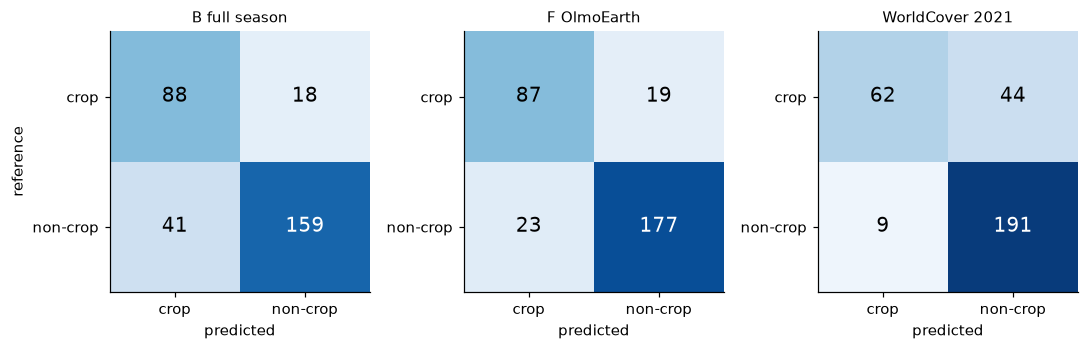

In [13]:
fig, axs = plt.subplots(1, 3, figsize=(10, 3.2))
for ax, m in zip(axs, ["RF B", "RF F", "WorldCover 2021"]):
    p = pred[m].to_numpy()
    cm = np.array([[((y == 1) & (p == 1)).sum(), ((y == 1) & (p == 0)).sum()],
                   [((y == 0) & (p == 1)).sum(), ((y == 0) & (p == 0)).sum()]])
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=200)
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, v, ha="center", va="center", fontsize=13, color="white" if v > 120 else "black")
    ax.set_xticks([0, 1], ["crop", "non-crop"])
    ax.set_yticks([0, 1], ["crop", "non-crop"])
    ax.set_xlabel("predicted")
    ax.set_title(NAMES[m], fontsize=10)
axs[0].set_ylabel("reference")
plt.tight_layout()
plt.show()

306 points give wide intervals, so differences need a paired test. The 95 % intervals are a bootstrap of
2 000 resamples of the test points (saved by `s12`/`s16`); the pairs use the exact McNemar test, which only
looks at the points where two maps disagree.

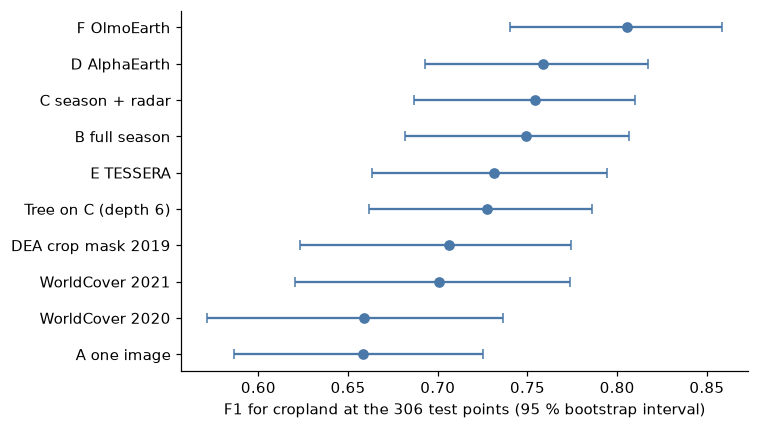

In [14]:
ci = saved.loc[maps].dropna(subset=["F1_crop_lo"])
fig, ax = plt.subplots(figsize=(7, 4))
order = ci.F1_crop.sort_values().index
ax.errorbar(ci.loc[order, "F1_crop"], range(len(order)),
            xerr=[ci.loc[order, "F1_crop"] - ci.loc[order, "F1_crop_lo"], ci.loc[order, "F1_crop_hi"] - ci.loc[order, "F1_crop"]],
            fmt="o", color="#4a78a8", capsize=3)
ax.set_yticks(range(len(order)), [NAMES[m] for m in order])
ax.set_xlabel("F1 for cropland at the 306 test points (95 % bootstrap interval)")
plt.tight_layout()
plt.show()

In [15]:
def mcnemar(a: str, b: str) -> dict:
    ra, rb = pred[a].to_numpy() == y, pred[b].to_numpy() == y
    only_a, only_b = int((ra & ~rb).sum()), int((~ra & rb).sum())
    return dict(a=NAMES[a], b=NAMES[b], a_right_b_wrong=only_a, b_right_a_wrong=only_b,
                p=binomtest(only_a, only_a + only_b, 0.5).pvalue)


pd.DataFrame([mcnemar(a, b) for a, b in [
    ("RF B", "RF A"), ("RF C", "RF B"), ("RF D", "RF B"), ("RF E", "RF B"), ("RF F", "RF B"),
    ("RF F", "RF D"), ("RF F", "RF E"), ("RF F", "WorldCover 2021"), ("RF F", "DEA crop mask 2019")]])

,a,b,a_right_b_wrong,b_right_a_wrong,p
0,B full season,A one image,44,21,0.006
1,C season + radar,B full season,18,17,1.000
2,D AlphaEarth,B full season,28,25,0.784
3,E TESSERA,B full season,23,25,0.885
4,F OlmoEarth,B full season,37,20,0.033
5,F OlmoEarth,D AlphaEarth,24,10,0.024
6,F OlmoEarth,E TESSERA,30,11,0.004
7,F OlmoEarth,WorldCover 2021,39,28,0.222
8,F OlmoEarth,DEA crop mask 2019,43,26,0.053


What the test says:

1. A full season of imagery beats one image clearly (B against A, p = 0.006). Adding radar (C) changes little.
2. OlmoEarth scored highest: F1 0.81 against 0.75 for the season (p = 0.03, or 0.10 corrected for three
   embeddings). AlphaEarth and TESSERA stay level
   with it.
3. OlmoEarth's main gain is fewer false alarms. It cuts the season's false alarms from 41 to 23 and calls 36 % of the
   points crop against a true 35 %, where B calls 42 %.
4. WorldCover 2021 raises few false alarms but misses 44 crop points against OlmoEarth's 19. Its gap to
   OlmoEarth is not significant (p = 0.22).

Validation overstated every set, the embeddings most (F1 about 0.89 to 0.91 on the folds against 0.73 to 0.81
on the test). The folds hold out 5 km cells of the training polygons, while the test points are a random
sample of all of Togo, including land unlike any training polygon.

The three labellers disagreed on 69 of the 306 points. Crop F1 on the unanimous and the split points is below.
Split points are mostly crop (56 of 69), so their crop F1 is high for every map; on the unanimous points,
where crop is rare, OlmoEarth's lower false-alarm rate shows most clearly.

In [16]:
sub = pd.concat([pd.read_csv(CHECKS / "test_scores.csv"), pd.read_csv(CHECKS / "olmoearth_test.csv")]).drop_duplicates(["map", "subset"])
sub[sub["map"].isin(["RF B", "RF D", "RF F", "WorldCover 2021"])].pivot(index="map", columns="subset", values="F1_crop")[["all", "unanimous", "split"]]

subset,all,unanimous,split
map,,,
RF B,0.749,0.687,0.827
RF D,0.759,0.677,0.857
RF F,0.806,0.797,0.816
WorldCover 2021,0.701,0.689,0.713


## 6. Information product: maps and cropland area of Savanes and Plateaux

`s13_maps.py` and `s17_maps_f.py` apply the set D and set F forests wall to wall at 10 m (about 26 000 km²).
A pixel count of a map is biased by its errors, so `s14_areas.py` also gives the error-adjusted area
(Olofsson et al. 2014): the test points inside a region are a random sample of it, and with the map classes
as strata the crop share is estimated from the reference labels at those points. A better map gives a
narrower interval, not a different expected value.

In [17]:
print(inspect.getsource(stratified))

def stratified(W: dict, y: np.ndarray, m: np.ndarray) -> tuple[float, float]:
    p, var = 0.0, 0.0
    for h, w in W.items():
        yh = y[m == h]
        if len(yh) == 0:
            return np.nan, np.nan  # a stratum without points: estimator undefined
        ph = yh.mean()
        p += w * ph
        var += w**2 * ph * (1 - ph) / max(len(yh) - 1, 1)
    return p, np.sqrt(var)



In [18]:
areas = pd.read_csv(CHECKS / "areas.csv")
rec = []
for region in ("Savanes", "Plateaux"):
    a = areas[(areas.region == region) & (areas["map"] == "f_crop")].iloc[0]
    pts = pred[pred.region == region]
    W = {1: a.mapped_share, 0: 1 - a.mapped_share}
    share, se = stratified(W, pts.label.to_numpy(), pts["RF F"].to_numpy())
    rec.append(dict(region=region, test_points=len(pts), mapped_share=a.mapped_share, adjusted_share=share,
                    lo=share - 1.96 * se, hi=share + 1.96 * se, adjusted_km2=share * a.region_km2,
                    saved_adjusted=a.adjusted_share))
pd.DataFrame(rec).set_index("region")

,test_points,mapped_share,adjusted_share,lo,hi,adjusted_km2,saved_adjusted
region,,,,,,,
Savanes,39,0.620,0.690,0.571,0.808,5977.694,0.690
Plateaux,106,0.423,0.365,0.304,0.425,6273.180,0.365


In [19]:
MAP_NAMES = {"wc2020": "WorldCover 2020", "wc2021": "WorldCover 2021", "dea_mask": "DEA crop mask 2019",
             "d_crop": "D AlphaEarth", "f_crop": "F OlmoEarth"}
pd.concat({"error-adjusted share": areas.pivot(index="map", columns="region", values="adjusted_share"),
           "mapped share": areas.pivot(index="map", columns="region", values="mapped_share")},
          axis=1).rename(index=MAP_NAMES).loc[list(MAP_NAMES.values())]

error-adjusted share         mapped share        
region                         Plateaux Savanes     Plateaux Savanes
map                                                                 
WorldCover 2020                   0.333   0.745        0.117   0.754
WorldCover 2021                   0.315   0.738        0.139   0.722
DEA crop mask 2019                0.310   0.718        0.308   0.512
D AlphaEarth                      0.353   0.720        0.438   0.645
F OlmoEarth                       0.365   0.690        0.423   0.620

Error-adjusted cropland is about 69 % of Savanes and 36 % of Plateaux, and all maps agree on it within their
intervals. The pixel counts differ much more: in Plateaux WorldCover 2021 maps 14 % of the land as crop,
while the two forests map 42 to 44 %. The intervals are wide (about ±12 and ±6 points) because only 39 and
106 test points fall in the two regions.

Quick looks of the set F map (from `s14_areas.py`):

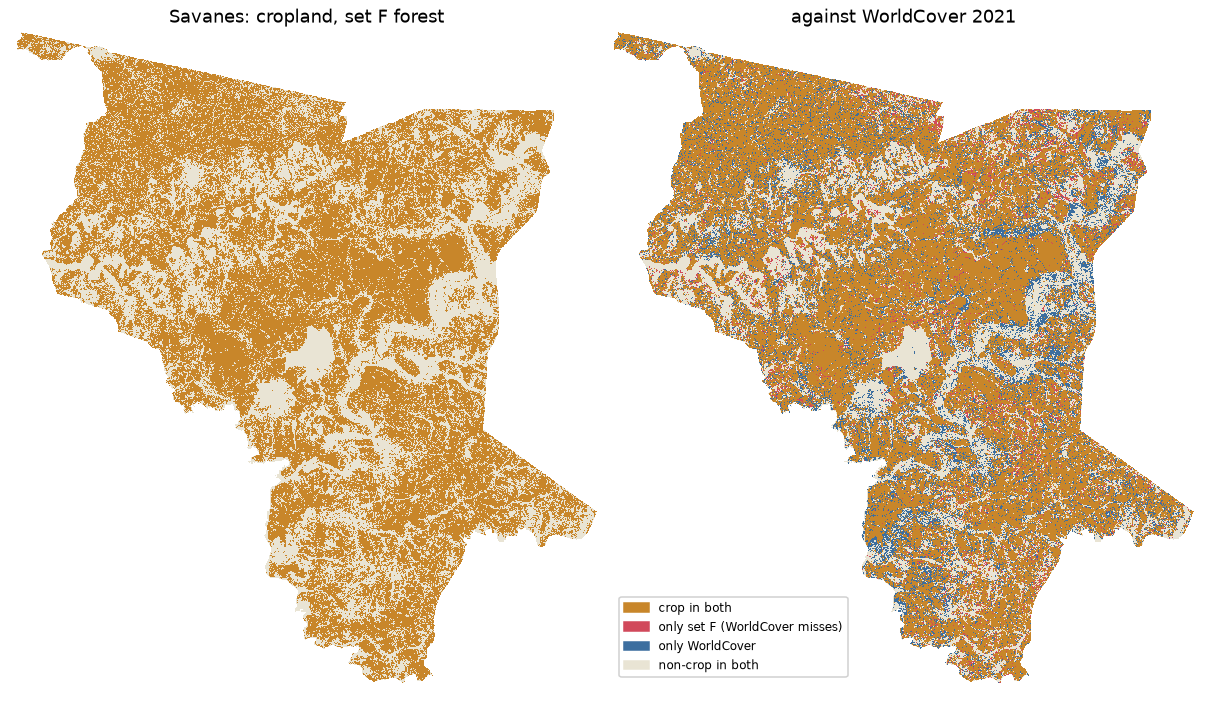

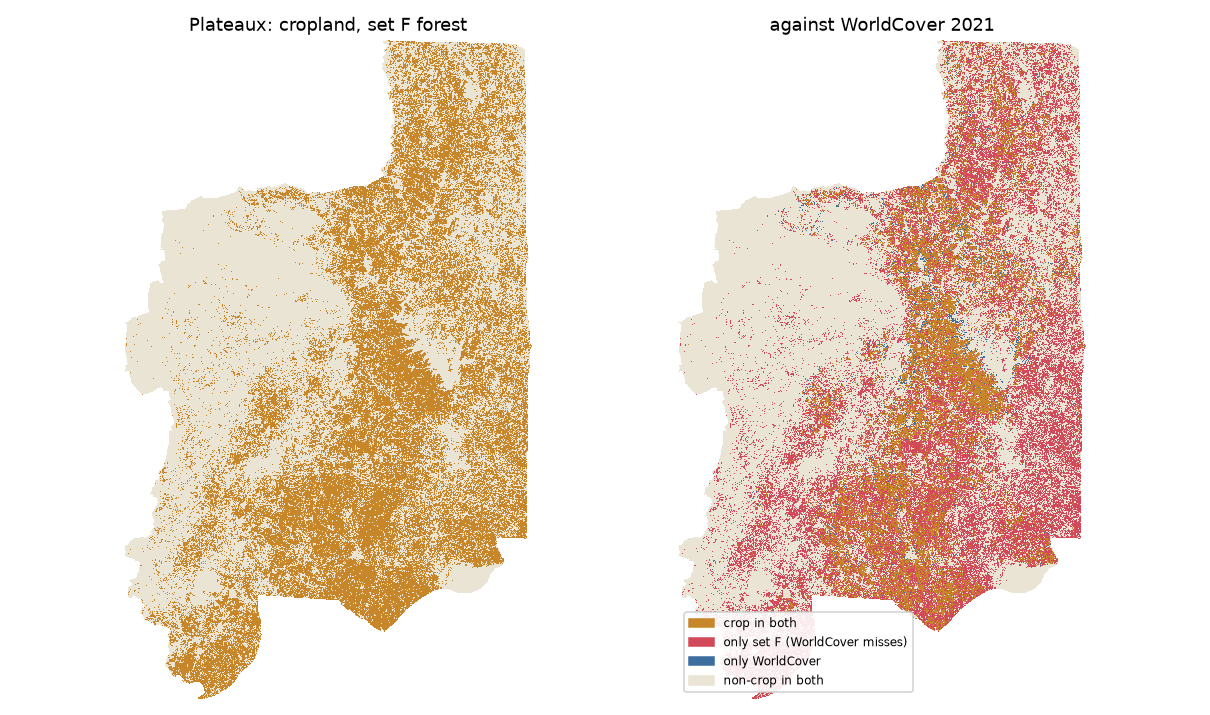

In [20]:
for region in ("Savanes", "Plateaux"):
    display(Image(filename=str(CHECKS / f"map_{region}_f.png"), width=700))

## 7. Error analysis

`s15_errors.py` looks at where the models go wrong, without refitting anything. It compares the forests on
sets C and D with WorldCover 2021 and the DEA mask. All four are right at 172 of the 306 points and all four
wrong at only 7. Where the models and WorldCover part ways, the models are right at 32 points and WorldCover
at 18, and almost all of the 32 are crop.

In [21]:
pd.read_csv(CHECKS / "errors_overlap.csv").set_index("pattern")

,crop,non-crop,All
pattern,,,
all right,37,135,172
all wrong,4,3,7
mixed,33,44,77
"models right, WC wrong",31,1,32
"models wrong, WC right",1,17,18
All,106,200,306


WorldCover's own class at the test points, against the outcome of the set D forest, shows what the forest
gains: 34 crop points that WorldCover calls grassland or shrubland, the parkland plots under scattered trees,
are found. Its false alarms fall on grassland, shrubland and tree cover alike.

In [22]:
pd.read_csv(CHECKS / "errors_wc_class.csv").fillna(0)

,label,wc_class,FN,FP,TN,TP
0,crop,cropland,8,0,0,54
1,crop,grassland,4,0,0,21
2,crop,shrubland,5,0,0,13
3,crop,tree cover,1,0,0,0
4,non-crop,built-up,0,0,1,0
5,non-crop,cropland,0,7,2,0
6,non-crop,grassland,0,11,30,0
7,non-crop,shrubland,0,11,49,0
8,non-crop,tree cover,0,9,78,0
9,non-crop,water,0,0,2,0


Accuracy by zone. The south (Maritime and southern Plateaux) is the weak spot: the forests call far more crop
than is there.

In [23]:
zone = pd.read_csv(CHECKS / "test_scores_zone.csv")
zone[zone["map"].isin(["RF B", "RF D", "WorldCover 2021"])].pivot(index="zone", columns="map", values="F1_crop")

map,RF B,RF D,WorldCover 2021
zone,,,
centre,0.853,0.867,0.622
kara,0.644,0.780,0.800
north,0.884,0.821,0.872
south,0.646,0.622,0.424


In [24]:
reg = pred.groupby("region").agg(n=("label", "size"), true_crop=("label", "mean"),
                                 called_B=("RF B", "mean"), called_F=("RF F", "mean"),
                                 called_WC2021=("WorldCover 2021", "mean"))
reg

,n,true_crop,called_B,called_F,called_WC2021
region,,,,,
Centrale,67,0.254,0.284,0.164,0.104
Kara,64,0.281,0.281,0.219,0.328
Maritime,30,0.267,0.533,0.633,0.000
Plateaux,106,0.330,0.434,0.377,0.151
Savanes,39,0.718,0.769,0.667,0.692


Calibration of the set D forest: probabilities between 0.5 and 0.8 are only about half right, so the
probability layer is a ranking, not a calibrated chance of crop.

In [25]:
pd.read_csv(CHECKS / "errors_calibration_D.csv")

,RF D p_crop,n,crop_share,mean_p
0,"(-0.001, 0.2]",129,0.039,0.056
1,"(0.2, 0.4]",26,0.192,0.280
2,"(0.4, 0.5]",25,0.320,0.446
3,"(0.5, 0.6]",14,0.429,0.563
4,"(0.6, 0.8]",45,0.533,0.680
5,"(0.8, 1.0]",67,0.866,0.923


## 8. Limitations and use

- Uncertainty. 306 test points, and only 39 in Savanes, give wide intervals. Most differences between the
  embeddings are not significant. OlmoEarth's gain over the season has p = 0.03, or 0.10 corrected for three
  embeddings.
- Data bias. Training polygons were drawn by experts where fields were clear, while the test points are random.
  Validation therefore overstated every model, and the label noise is real: the three labellers split on 69
  points.
- Transferability. Maritime has few training polygons and the forests overcall crop there (63 % called against
  27 % true for OlmoEarth). The map should not be used there without new labels.
- Set F was added after the test of A to E. Its setting was fixed in advance, but the comparison is no longer a
  single pre-registered test.
- Pretraining is a plausible reason for OlmoEarth's lead, since only it learned from global crop and land-cover
  maps (WorldCereal, WorldCover). That also means it may share those maps' blind spots.
- Independence. No test point lies inside a WorldCereal reference polygon, although 1 274 of the 1 276 training
  polygons are in that repository. OlmoEarth keeps its lead on the 960 polygons WorldCereal did not select
  (leave-one-region-out F1 0.89 against 0.86 for TESSERA).

Use: the error-adjusted areas are usable as regional cropland statistics with their intervals, and the set F
map can add the parkland farms that WorldCover misses in Plateaux to water balance estimates. The next step for a
national map is labels in Maritime and a probability calibration.

## References

- Kerner, H. et al. (2020). Rapid response crop maps in data sparse regions. KDD Humanitarian Mapping Workshop.
  Labels: Zenodo 10.5281/zenodo.3836629 and 10.5281/zenodo.4680394 (CC BY 4.0).
- Olofsson, P. et al. (2014). Good practices for estimating area and assessing accuracy of land change. Remote
  Sensing of Environment 148, 42-57.
- Zanaga, D. et al. (2022). ESA WorldCover 10 m 2021 v200.
- Digital Earth Africa (2019). Cropland extent map (crop mask) for Africa, 2019.
- Brown, C. F. et al. (2025). AlphaEarth Foundations. arXiv 2507.22291.
- Feng, Z. et al. (2025). TESSERA. arXiv 2506.20380.
- OlmoEarth Team (2026). OlmoEarth. arXiv 2610.32294.